# Estimate Melt Density Assignment
<br>
This assignment has been adapted from an excel-based version within the 
SSAC Physical Volcanology Modules collection, available through SERC (https://serc.carleton.edu/sp/ssac/volcanology/volcmodules.html). The collection was 
developed by Chuck Connor (University of South Florida) and Peter LaFemina (Penn State). Connor
is the original author of this particular lesson on melt density.
<br><br>
For each question, read the table or figure produced by the code cell, then write your answer
in a Markdown cell below the question (double-click the cell to edit, then run it to render).

Run the setup cell once (Cell ▸ Run All), then work through the questions in order.


## Setup

This cell defines the melt-density function used throughout the assignment. It stores the oxide
list, the molecular masses $M_i$, the reference molar volumes $V_0$, and the thermal-expansion
and compressibility coefficients, then wraps the tutorial equation
$\rho=\sum_i X_i M_i / V_i$ in a single function `melt_density(wt, T_K, P_GPa)`. It also stores
three reference compositions (basalt, andesite, rhyolite) so each question can call the same
function with different inputs.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OXIDES = ['SiO2','TiO2','Al2O3','Fe2O3','FeO','MnO','MgO','CaO','Na2O','K2O','H2O','CO2']
M_g  = np.array([60.08,79.88,101.96,159.69,71.85,70.94,40.30,56.08,61.99,94.20,18.02,44.01])
V0   = np.array([26.75,22.45,37.80,44.40,13.94,13.94,12.32,16.95,29.03,46.30,26.27,33.00])   # 1e-6 m3/mol
dVdT = np.array([0.00,7.24,0.00,9.09,2.92,2.92,3.27,3.74,7.68,12.08,9.46,0.00])               # 1e-9 m3/mol K
dVdP = np.array([-1.89,-2.31,-2.26,-2.53,-0.45,-0.45,0.27,0.34,-2.40,-6.75,-3.15,0.00])        # 1e-6 m3/mol GPa

def melt_density(wt, T_K, P_GPa):
    wt = np.asarray(wt, float); mol = wt/M_g; X = mol/mol.sum()
    V = V0*1e-6 + dVdT*1e-9*(T_K-1673) + dVdP*1e-6*P_GPa
    return np.sum(X*(M_g*1e-3)/V)

comps = {
 'Basalt':   [48.77,1.15,15.90,1.33,8.62,0.17,9.67,11.16,2.43,0.08,0.03,0.01],
 'Andesite': [59.89,0.95,17.07,3.31,3.00,0.12,3.25, 5.67,3.95,2.47,0.10,0.00],
 'Rhyolite': [70.87,0.10,14.78,2.69,0.00,0.06,0.10, 0.34,6.47,4.21,0.33,0.00],
}
print('Setup ready.')

Setup ready.


## Question 1: Three Melts at the Same Pressure

This cell evaluates the density model for a basalt at 1250 °C, an andesite at 1000 °C, and a
rhyolite at 900 °C, all at $P = 0.2$ GPa. It reports the three densities in a table and as a bar
chart so their differences can be compared directly.


,T (deg C),density (kg/m3)
Basalt,1250,2886.8
Andesite,1000,2626.7
Rhyolite,900,2355.7


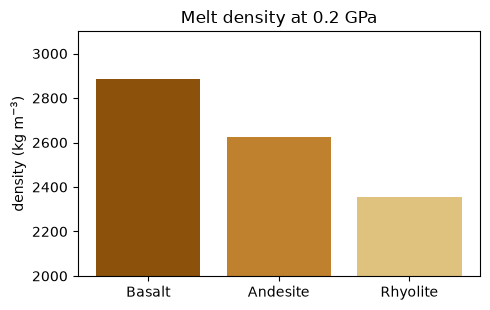

In [2]:
# provided: densities of the three melts at 0.2 GPa
temps_C = {'Basalt':1250, 'Andesite':1000, 'Rhyolite':900}
rows = {name: melt_density(wt, temps_C[name]+273, 0.2) for name,wt in comps.items()}
tbl = pd.DataFrame({'T (deg C)': temps_C, 'density (kg/m3)': {k: round(v,1) for k,v in rows.items()}})
display(tbl)

fig, ax = plt.subplots(figsize=(5,3.2))
ax.bar(rows.keys(), rows.values(), color=['#8c510a','#bf812d','#dfc27d'])
ax.set_ylabel('density (kg m$^{-3}$)'); ax.set_ylim(2000,3100)
ax.set_title('Melt density at 0.2 GPa'); plt.tight_layout(); plt.show()

**Question 1.** The three melts have clearly different densities. Rank them, and explain why the
density follows this order in terms of their compositions (which oxides make a melt denser or
lighter?). Which of the three would rise most easily through the crust, and why?


## Question 2: Density Versus Temperature

This cell holds the basalt composition and pressure fixed at $P = 1$ GPa and evaluates the
density as temperature rises from 1100 °C to 1400 °C. It plots density against temperature so the
trend can be read off directly.


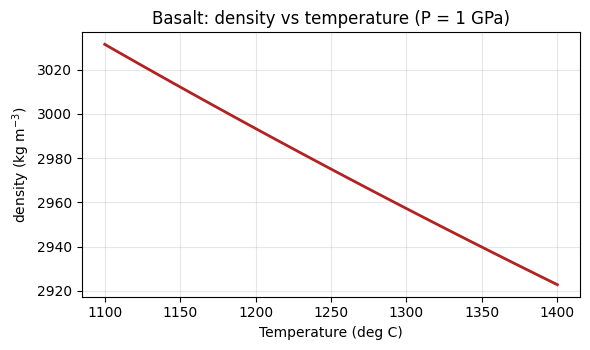

In [3]:
# provided: basalt density vs temperature at 1 GPa
T_C = np.arange(1100, 1401, 5)
rho_T = [melt_density(comps['Basalt'], t+273, 1.0) for t in T_C]
plt.figure(figsize=(6,3.6))
plt.plot(T_C, rho_T, color='firebrick', lw=2)
plt.xlabel('Temperature (deg C)'); plt.ylabel('density (kg m$^{-3}$)')
plt.title('Basalt: density vs temperature (P = 1 GPa)'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Question 2.** Describe how density changes as temperature increases, and explain what causes
this. *(Hint: consider what heating does to the molar volume of each oxide.)*


## Question 3: Density Versus Pressure

This cell holds the basalt composition and temperature fixed at 1400 °C and evaluates the density
as pressure rises from 0.0001 GPa to 3 GPa. It plots density against pressure.


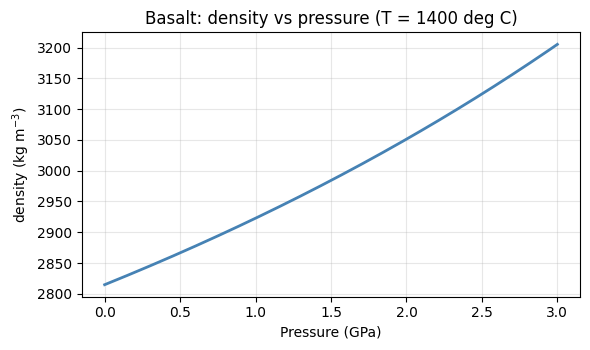

In [4]:
# provided: basalt density vs pressure at 1400 deg C
P_arr = np.linspace(0.0001, 3.0, 200)
rho_P = [melt_density(comps['Basalt'], 1400+273, p) for p in P_arr]
plt.figure(figsize=(6,3.6))
plt.plot(P_arr, rho_P, color='steelblue', lw=2)
plt.xlabel('Pressure (GPa)'); plt.ylabel('density (kg m$^{-3}$)')
plt.title('Basalt: density vs pressure (T = 1400 deg C)'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Question 3.** Describe how density changes as pressure increases, and explain what causes this.
How does this contrast with the effect of temperature in Question 2?


## Question 4: Density Versus Water Content

This cell takes the rhyolite at 900 °C and 0.0001 GPa and raises its water content from 0.5 to
6 wt %, transferring the added water from SiO₂ so the total stays at 100 percent. It plots density
against water content.


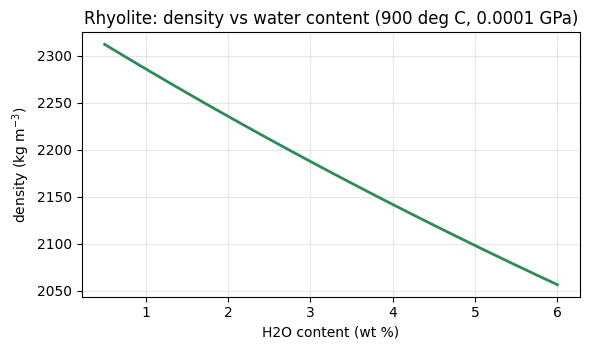

In [5]:
# provided: rhyolite density vs water content
iH2O, iSiO2 = OXIDES.index('H2O'), OXIDES.index('SiO2')
base = np.array(comps['Rhyolite'], float)
waters = np.arange(0.5, 6.01, 0.25)
rho_w = []
for w in waters:
    c = base.copy()
    c[iSiO2] = c[iSiO2] + c[iH2O] - w   # move the difference from SiO2 into H2O
    c[iH2O]  = w
    rho_w.append(melt_density(c, 900+273, 0.0001))
plt.figure(figsize=(6,3.6))
plt.plot(waters, rho_w, color='seagreen', lw=2)
plt.xlabel('H2O content (wt %)'); plt.ylabel('density (kg m$^{-3}$)')
plt.title('Rhyolite: density vs water content (900 deg C, 0.0001 GPa)'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Question 4.** Describe how density changes as water content increases, and explain why.


## Question 5: Putting It Together

Magma ascent is driven by the density difference between the melt and the surrounding crust
(about 2800 kg m⁻³). Using your answers above, explain how composition, temperature, pressure, and
water content each influence whether a silicate melt will tend to rise or stall.
